# 03 · Potential evapotranspiration (Hargreaves)

$$PET = 0.0023 \cdot 0.408\,R_a \cdot (T + 17.8) \cdot \sqrt{T_{max} - T_{min}} \quad [mm/day]$$

multiplied by the number of days in the month. $R_a$ (MJ m⁻² day⁻¹) is computed on the 15th of each
month with FAO-56 eq. 21 (`extraterrestrial_radiation`, given). $0.408$ converts MJ m⁻² day⁻¹ to mm/day.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.pet import extraterrestrial_radiation, pet_monthly

clim = pd.read_csv(PROC / "climate.csv", index_col=0, parse_dates=True)
lat = case["latitude_deg"]
doy15 = pd.date_range("2001-01-15", periods=12, freq="MS") + pd.Timedelta(days=14)
ra = extraterrestrial_radiation(lat, doy15.day_of_year)

pet = pet_monthly(clim.t_c, clim.tmax_c, clim.tmin_c, lat)
pet.to_csv(PROC / "pet.csv")
pet.describe().round(1)

count    480.0
mean     101.3
std       56.7
min       26.9
25%       43.5
50%       91.6
75%      156.3
max      219.4
Name: pet, dtype: float64

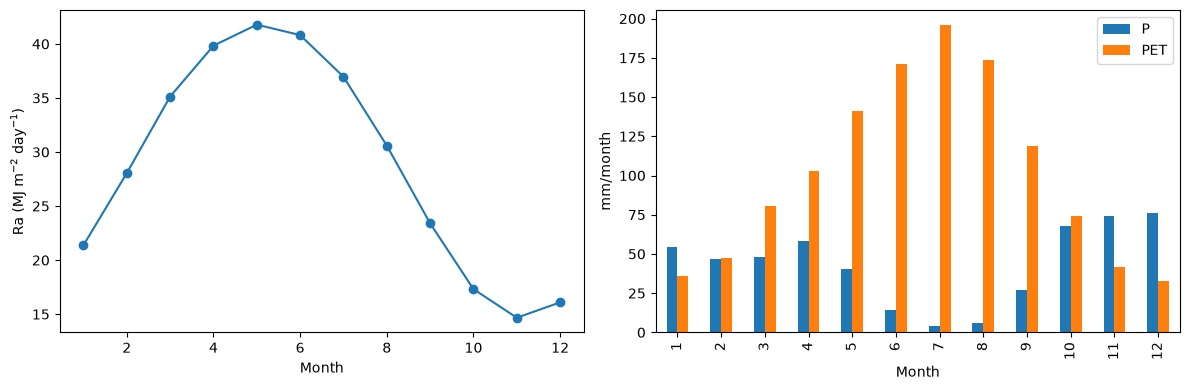

In [3]:
monthly = pd.DataFrame({"P": clim.p_mm, "PET": pet}).groupby(clim.index.month).mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 13), ra, "o-")
ax[0].set_xlabel("Month"); ax[0].set_ylabel("Ra (MJ m$^{-2}$ day$^{-1}$)")
monthly.plot.bar(ax=ax[1], color=["tab:blue", "tab:orange"])
ax[1].set_xlabel("Month"); ax[1].set_ylabel("mm/month")
plt.tight_layout()

In [4]:
# TODO: List the calendar months in which mean PET > mean P.
# In: monthly (DataFrame with columns P, PET by month)
# Out: dry_months (list of month numbers)
dry_months = monthly.index[monthly["PET"] > monthly["P"]].tolist()
print("Months with PET > P:", dry_months)
print(f"Annual PET {pet.groupby(pet.index.year).sum().mean():.0f} mm, annual P {clim.p_mm.groupby(clim.index.year).sum().mean():.0f} mm")

Months with PET > P: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Annual PET 1216 mm, annual P 518 mm


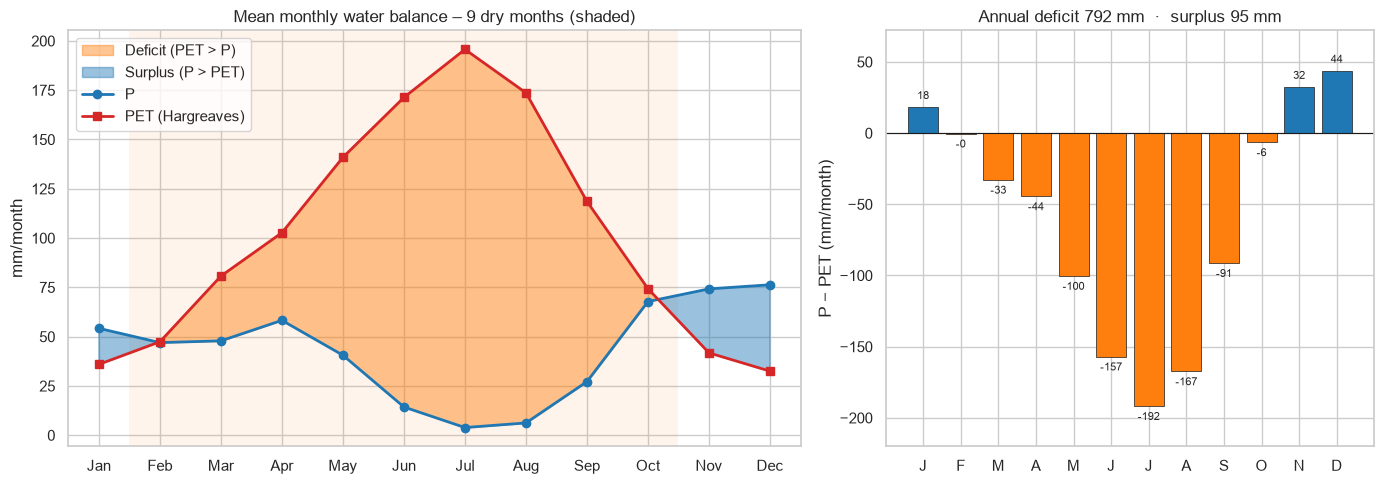

In [5]:
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Fine x-grid so the surplus/deficit shading switches exactly where the curves cross
m = np.arange(1, 13)
x = np.linspace(1, 12, 400)
P_s = np.interp(x, m, monthly["P"])
PET_s = np.interp(x, m, monthly["PET"])

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 2]})

# ── Left: P and PET with surplus / deficit shading ──────────────────────────
a = ax[0]
for mo in dry_months:
    a.axvspan(mo - 0.5, mo + 0.5, color="tab:orange", alpha=0.08, lw=0)
a.fill_between(x, P_s, PET_s, where=PET_s > P_s, color="tab:orange", alpha=0.45, label="Deficit (PET > P)")
a.fill_between(x, P_s, PET_s, where=PET_s <= P_s, color="tab:blue", alpha=0.45, label="Surplus (P > PET)")
a.plot(m, monthly["P"], "o-", color="tab:blue", lw=2, label="P")
a.plot(m, monthly["PET"], "s-", color="tab:red", lw=2, label="PET (Hargreaves)")
a.set(xticks=m, xticklabels=MONTHS, xlim=(0.5, 12.5), ylabel="mm/month",
      title=f"Mean monthly water balance – {len(dry_months)} dry months (shaded)")
a.legend(loc="upper left")

# ── Right: P − PET per month as diverging bars ──────────────────────────────
b = ax[1]
diff = monthly["P"] - monthly["PET"]
b.bar(m, diff, color=np.where(diff < 0, "tab:orange", "tab:blue"), edgecolor="k", lw=0.5)
b.axhline(0, color="k", lw=0.8)
for mo, d in diff.items():
    b.text(mo, d + (4 if d >= 0 else -4), f"{d:.0f}", ha="center",
           va="bottom" if d >= 0 else "top", fontsize=8)
b.set(xticks=m, xticklabels=[s[0] for s in MONTHS], ylabel="P − PET (mm/month)",
      title=f"Annual deficit {-diff[diff < 0].sum():.0f} mm  ·  surplus {diff[diff > 0].sum():.0f} mm")
b.margins(y=0.12)

plt.tight_layout(); plt.show()


**Answer.**

**Left:** the P and PET curves, coloured orange where PET is above P (deficit) and blue where P is above PET (surplus). Your dry months (February to October, 9 months) are also lightly shaded.

**Right:** P − PET for each month as bars, with the value written on each bar. The title gives the yearly totals: a deficit of about 792 mm against a surplus of only about 95 mm.